# JS11 - Praktikum 1: SVM Data Dummy Linier
**Mata Kuliah:** Pembelajaran Mesin  
**Nama:** Aryaputra | **NIM:** 244107020127  

---
### Deskripsi
Penerapan Support Vector Classifier (SVC) kernel linier pada data dummy `make_blobs`, visualisasi margin maksimal dan identifikasi titik *support vectors*.


Support Vectors Titik:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


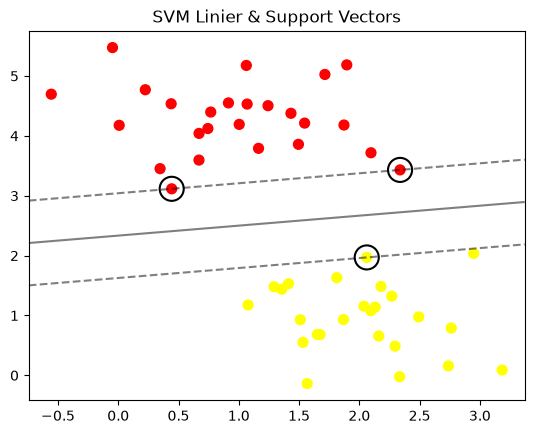

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 1. Data Dummy
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

# 2. Fungsi Visualisasi Margin
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None: ax = plt.gca()
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    x = np.linspace(xlim[0], xlim[1], 30)
    y_line = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y_line, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)
    ax.contour(X_grid, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=300, linewidth=1.5, facecolors='none', edgecolors='black')

model = SVC(kernel='linear', C=1E10).fit(X, y)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title("SVM Linier & Support Vectors")
plt.show()

print("Support Vectors Titik:")
print(model.support_vectors_)
